# Aula 1 · Ensinar a máquina com exemplos

**VERSÃO DO FACILITADOR: tudo resolvido, com notas.** Não copiar para os computadores dos alunos.

**10 minutos (11:40–11:50) · aula guiada, em pares** · a seguir: a Prática 1

**O que vamos fazer:** ensinar o computador a reconhecer a água numa imagem de satélite. Não vamos escrever a regra: damos-lhe **exemplos com a resposta certa** e ele descobre a regra sozinho. É isto o Machine Learning.

**Os dados:** `incomati_2026_cheia.npz` (a imagem do satélite da cheia de 24/01/2026) e `exemplos_da_equipa.json` (15 pontos de água e 15 de não água, com a resposta certa).  
**Treino e teste:** ainda não separamos: a árvore aprende com todos os exemplos e medimos o acerto nos mesmos. A Aula 2 mostra porque é que isso engana.  
**O algoritmo:** árvore de decisão (classificação: água ou não água).

| Palavra nova | O que quer dizer |
| --- | --- |
| **exemplo** | um caso que mostramos ao computador (aqui, um píxel da imagem) |
| **característica** | o que se mede em cada exemplo (aqui, as 5 cores medidas pelo satélite) |
| **rótulo** | a resposta certa de cada exemplo (aqui, 1 = água e 0 = não água) |
| **modelo** | a regra que o computador aprende com os exemplos |
| **treinar** | dar os exemplos ao modelo para ele aprender |
| **prever** | usar o modelo para dar a resposta num caso novo |

**Como trabalhar:** esta é a **aula guiada**: o facilitador mostra no projector e vocês acompanham.
Cliquem numa célula de código (as cinzentas) e carreguem em **Shift + Enter** para a correr, sempre **por ordem**, de
cima para baixo. A seguir vem a **prática**, em que são vocês a escrever o código. Guardem com **Ctrl + S**.

> **Nota para o facilitador.** Objectivo: que os alunos percebam as seis palavras da tabela. Leiam a tabela em voz alta com a turma antes de começar. Tempo: 10 minutos, no projector; os pares correm as células ao mesmo tempo. A seguir, a Prática 1, em que escrevem o código sozinhos.

## Passo 1 · Abrir as ferramentas

As ferramentas abrem as imagens, desenham os mapas e corrigem os exercícios.

In [1]:
import os, sys
for pasta in [".", os.path.join("..", "..", "2_pratica")]:          # a pasta onde está o ferramentas.py
    if os.path.exists(os.path.join(pasta, "ferramentas.py")):
        sys.path.insert(0, pasta)
        break
from ferramentas import *      # as ferramentas da aula
print("Ferramentas prontas.")

Ferramentas prontas.


## Passo 2 · A imagem do satélite

O satélite **Sentinel-2** fotografou o rio Incomáti, em Marracuene, a **24 de Janeiro de 2026**, no meio da cheia. Cada quadradinho da imagem é um **píxel** de 30 m × 30 m. Os círculos são pontos de **água** marcados pela equipa; os quadrados são pontos de **não água** (terra, plantas, casas).

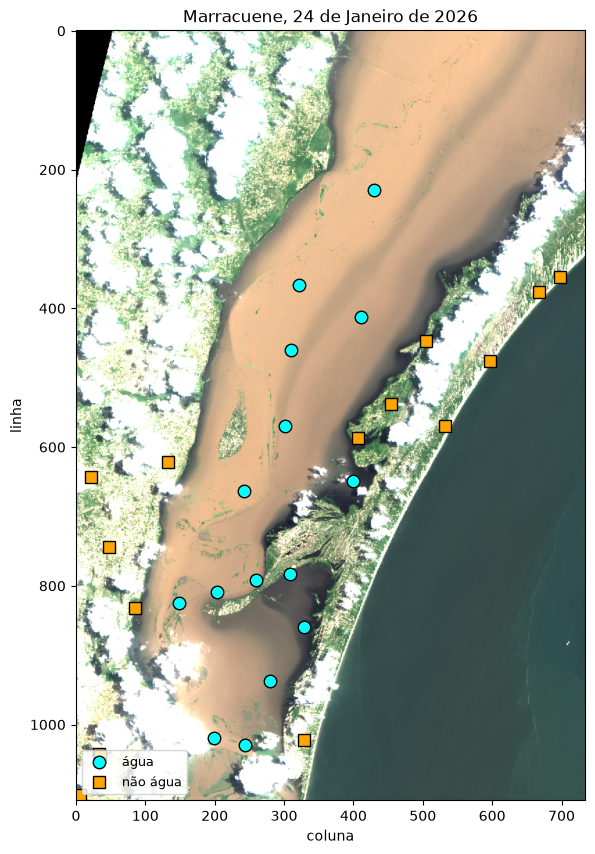

In [2]:
cheia = carregar("incomati_2026_cheia.npz")
pontos = pontos_da_equipa(2026)
ver_imagem(cheia, "Marracuene, 24 de Janeiro de 2026", pontos["agua"], pontos["nao_agua"])

## Passo 3 · Uma imagem é uma tabela de números

O computador não vê cores: vê números. Em cada píxel, o satélite mede 5 bandas: azul, verde, vermelho e dois infravermelhos que os nossos olhos não vêem, o **NIR** e o **SWIR**. Comparemos um píxel de água com um de terra.

In [3]:
l, c = pontos["agua"][0]            # um ponto de água: linha e coluna
l2, c2 = pontos["nao_agua"][0]      # um ponto de terra
pd.DataFrame({"píxel de água": [cheia[b][l, c] for b in BANDAS],
              "píxel de terra": [cheia[b][l2, c2] for b in BANDAS]}, index=BANDAS)

,píxel de água,píxel de terra
azul,0.087,0.077
verde,0.112,0.111
vermelho,0.140,0.082
nir,0.067,0.383
swir,0.011,0.264


Olhem para a última linha, o **SWIR**: na água é quase 0, porque a água absorve este infravermelho; na terra é muito maior. Guardem esta ideia.

> **Nota para o facilitador.** Resultado esperado: SWIR da água 0,011 e da terra 0,264. Pergunte à turma: «qual das linhas separa melhor a água da terra?» e deixe-os descobrir o SWIR.

## Passo 4 · Os exemplos, com os rótulos

À volta de cada ponto marcado tiramos 25 píxeis (um quadrado de 5 × 5). Fica uma tabela: uma linha por exemplo, as 5 **características** e o **rótulo** (1 = água, 0 = não água).

In [4]:
exemplos = tabela_de_exemplos(cheia, pontos["agua"], pontos["nao_agua"])
print("Número de exemplos:", len(exemplos))
print("De água:", (exemplos["rótulo"] == 1).sum(), "   De não água:", (exemplos["rótulo"] == 0).sum())
exemplos.sample(8, random_state=1)        # 8 linhas da tabela, ao acaso

Número de exemplos: 738
De água: 375    De não água: 363


,azul,verde,vermelho,nir,swir,rótulo
679,0.079,0.090,0.102,0.164,0.188,0
257,0.107,0.130,0.155,0.076,0.020,1
526,0.097,0.104,0.110,0.146,0.154,0
496,0.047,0.068,0.040,0.457,0.181,0
427,0.067,0.093,0.077,0.346,0.241,0
349,0.039,0.039,0.038,0.016,0.009,1
434,0.085,0.111,0.100,0.368,0.278,0
189,0.085,0.111,0.138,0.065,0.011,1


> **Nota para o facilitador.** Resultado esperado: 738 exemplos, 375 de água e 363 de não água. Mostre que cada linha é um píxel e que a última coluna é a resposta certa.

## Passo 5 · Uma regra feita por nós

Antes da máquina, tentemos nós. A nossa regra: **se o SWIR for menor do que 0,10, é água**. Quantos exemplos acerta? (Em Python, as décimas escrevem-se com ponto: 0.10.)

In [5]:
limite = 0.10
resposta_da_regra = (exemplos["swir"] < limite).astype(int)      # 1 = água, 0 = não água
print("A regra acerta", percentagem(acerto(exemplos["rótulo"], resposta_da_regra)), "dos exemplos.")

A regra acerta 98,2 % dos exemplos.


## Passo 6 · A máquina aprende a regra sozinha

Agora damos os exemplos a uma **árvore de decisão**. Ela procura a pergunta que melhor separa a água da não água. Isto é **treinar** o modelo. `X` são as características e `y` são os rótulos.

In [6]:
from sklearn.tree import DecisionTreeClassifier, export_text

X = exemplos[BANDAS]            # as características
y = exemplos["rótulo"]          # as respostas certas
arvore = DecisionTreeClassifier(max_depth=2, random_state=0)
arvore.fit(X, y)                # treinar: aprender com os exemplos
print(export_text(arvore, feature_names=BANDAS).replace("class: 1", "ÁGUA").replace("class: 0", "NÃO ÁGUA"))
print("A árvore acerta", percentagem(acerto(y, arvore.predict(X))), "dos exemplos.")

|--- swir <= 0.04
|   |--- ÁGUA
|--- swir >  0.04
|   |--- NÃO ÁGUA

A árvore acerta 100,0 % dos exemplos.


A árvore escolheu sozinha o **SWIR**, como nós, mas encontrou um limite melhor. Ninguém lhe disse que o SWIR era importante: aprendeu com os exemplos.

> **Nota para o facilitador.** A regra feita à mão acerta 98,2 %. A árvore aprende «SWIR ≤ 0,04 → água» e acerta 100,0 %. Ligue ao slide da árvore de decisão (Módulo 2). Avise já: este acerto é nos mesmos exemplos do treino; a Aula 2 explica porque é que isso não chega.

## Passo 7 · Prever: o mapa da água

O modelo treinado pode responder para **todos** os píxeis da imagem, também os que nunca viu. Isto é **prever**.

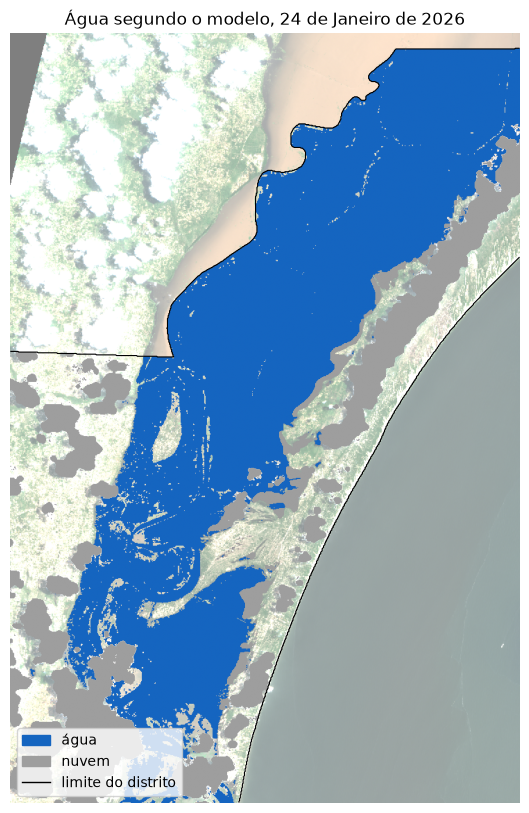

Água no distrito: 20 300 hectares


In [7]:
mapa_cheia = prever_mapa(arvore, cheia)
ver_mapa(mapa_cheia, cheia, "Água segundo o modelo, 24 de Janeiro de 2026")
print("Água no distrito:", numero(hectares(mapa_cheia, cheia)), "hectares")

> **Nota para o facilitador.** Resultado esperado: cerca de 20 300 hectares de água. O distrito tem cerca de 70 600 hectares (706 km²): a cheia cobriu perto de um terço.

## O que aprendemos

- O computador aprende com **exemplos** que têm a resposta certa (os **rótulos**).
- Em cada exemplo, olha para as **características**: aqui, as 5 bandas do satélite.
- Ao **treinar**, o **modelo** encontra a regra sozinho: aqui, «SWIR baixo é água».
- Depois **prevê** a resposta em casos que nunca viu: todos os píxeis da imagem.
- Atenção: medimos o acerto nos **mesmos** exemplos do treino. Na Aula 2 vemos porque é que isso não chega.

## Guardar os modelos e as separações (só na versão do facilitador)

Ficam nas pastas `modelos_treinados/` e `separacoes/`, ao lado deste notebook. Para usar um modelo noutro notebook: `modelo = joblib.load("modelos_treinados/...joblib")`.

In [8]:
import joblib
os.makedirs("modelos_treinados", exist_ok=True)
os.makedirs("separacoes", exist_ok=True)
joblib.dump(arvore, "modelos_treinados/aula1_arvore_de_decisao.joblib")
exemplos.to_csv("separacoes/aula1_exemplos_2026.csv", index=False)
print("Guardado em modelos_treinados/ e separacoes/.")

Guardado em modelos_treinados/ e separacoes/.


## Se aparecer um erro

Leiam a **última linha** da mensagem vermelha.

| A última linha diz | O que fazer |
| --- | --- |
| `NameError: name '...' is not defined` | Saltaram uma célula. Corram as células por ordem, a partir do Passo 1. |
| `FileNotFoundError: Não encontrei ...` | Abram o notebook a partir da pasta `Workshop_2/2_pratica`. |
| `ModuleNotFoundError` | Falta uma biblioteca neste computador: chamem um facilitador. |
| `NotFittedError` ou «O modelo ainda não foi treinado» | Falta treinar o modelo: corram a célula com `.fit(...)`. |
| `SyntaxError` | Falta uma aspa, um parêntese ou uma vírgula. Comparem com o exemplo. |
| «Falta preencher» | Troquem os `...` pela vossa resposta. |

Se nada resultar: menu **Kernel**, depois **Restart Kernel and Run All Cells**.